# 1. Environment

In [2]:
import os
import shutil
from pathlib import Path
import re

import json
import pandas as pd
import numpy as np

from tqdm import tqdm

from collections import defaultdict, Counter
from typing import Tuple, Optional

import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
import plotly.graph_objects as go

In [2]:
os.chdir("C:\\Users\\yatsyk\\Documents\\NextCloud_Synchro\\passim_BoH\\")

# 2. Data

## 2.1. Helper functions

### 2.1.1. Drop annotations rows with low confidence

In [4]:
def drop_low_confidence(group):
    if (group['confidence'] != 0.5).any():
        return group[group['confidence'] != 0.5]
    else:
        return group  # keep the group as-is if all rows have confidence == 0.5

The structure of the JSON files generated by passim assumes the existence of a source text (src) and texts that cite it.</br>
We cannot make passim always treat series == source as the actual source, so sometimes manuscripts end up playing that role.</br>
We will separately handle the cases where the source is a reference text and where the source is a manuscript.

### 2.1.1. Jsons to df (ref series == source)

In [5]:
def create_dataframe_from_json_source_is_ref(
    json_filepath: str,
    ref_texts_length_df: pd.DataFrame,
    pages_length_df: pd.DataFrame,
    ref_path: str
) -> pd.DataFrame:

    with open(json_filepath, "r", encoding="utf-8") as f:
        json_data = json.load(f)

    # Length dictionaries for quick access
    ref_texts_len_dict = ref_texts_length_df.set_index('ref_text_id')['text_length'].to_dict()
    pages_len_dict = pages_length_df.set_index('page_ordering')['HTR_text_length'].to_dict()

    # Group by cluster
    clusters = {}
    for item in json_data:
        clusters.setdefault(item['cluster'], []).append(item)

    rows = []

    for cluster_items in clusters.values():
        # Find source item
        source_items = [item for item in cluster_items if item.get("series") == "source"]
        if not source_items:
            continue

        source_item = source_items[0]
        source_uid = source_item.get("uid")
        ref_text_id = source_item.get("id")

        if ref_text_id not in ref_texts_len_dict:
            continue

        # Go through all pages referring to this source in this cluster
        for page in cluster_items:
            if page.get("series") == "source":
                continue
            if not isinstance(page.get("src"), list) or not page["src"]:
                continue

            matching_src = next((s for s in page["src"] if s.get("uid") == source_uid), None)
            if not matching_src:
                continue

            page_ordering = page.get("id")
            ms_arkindex_id = page.get("series")
            if page_ordering not in pages_len_dict or ms_arkindex_id is None:
                continue

            rows.append({
                'source_text_id': ref_text_id,
                'page_ordering': page_ordering,
                'ms_arkindex_id': ms_arkindex_id,
                'text_match_begin_offset': matching_src.get("begin"),
                'text_match_end_offset': matching_src.get("end"),
                'page_match_begin_offset': page.get("begin"),
                'page_match_end_offset': page.get("end"),
                'Nature': 'original prediction',
                'source_dataset': 'passim'
            })

    df = pd.DataFrame(rows)

    if not df.empty:
        df["source_text_id"] = df["source_text_id"].astype("Int64", errors="ignore")

        # Fetch Arkindex IDs from the reference file
        ref = pd.read_csv(ref_path, sep="\t")
        if "Work H-ID" in ref.columns:
            ref["Work H-ID"] = ref["Work H-ID"].astype("Int64", errors="ignore")
            df = pd.merge(
                df,
                ref[["Work H-ID", "ID Arkindex"]],
                left_on="source_text_id",
                right_on="Work H-ID",
                how="left"
            )
            df.drop(columns=["Work H-ID"], inplace=True, errors="ignore")
    else:
        df = pd.DataFrame(columns=[
            'source_text_id', 'page_ordering', 'ms_arkindex_id',
            'text_match_begin_offset', 'text_match_end_offset',
            'page_match_begin_offset', 'page_match_end_offset',
            'ID Arkindex', 'source_dataset', 'Nature'
        ])

    return df


### 2.1.2. Jsons to df (ref series != source)

In [6]:
def create_dataframe_from_json_source_is_page(
    json_filepath: str,
    ref_texts_length_df: pd.DataFrame,
    pages_length_df: pd.DataFrame,
    ref_path: str
) -> pd.DataFrame:

    with open(json_filepath, "r", encoding="utf-8") as f:
        json_data = json.load(f)

    # Length dictionaries for quick access
    ref_texts_len_dict = ref_texts_length_df.set_index("ref_text_id")["text_length"].to_dict()
    pages_len_dict = pages_length_df.set_index("page_ordering")["HTR_text_length"].to_dict()

    # Index items by UID
    uid_map = {item["uid"]: item for item in json_data}
    rows = []

    for item in json_data:
        if item.get("series") != "source":
            continue
        if not isinstance(item.get("src"), list) or not item["src"]:
            continue

        ref_text_id = item.get("id")
        if ref_text_id not in ref_texts_len_dict:
            continue

        text_match_begin_offset = item.get("begin")
        text_match_end_offset = item.get("end")

        for src in item["src"]:
            page_uid = src.get("uid")
            if page_uid not in uid_map:
                continue

            page = uid_map[page_uid]
            if page.get("series") == "source":
                continue

            page_ordering = page.get("id")
            ms_arkindex_id = page.get("series")
            if page_ordering not in pages_len_dict or ms_arkindex_id is None:
                continue

            row = {
                "source_text_id": ref_text_id,
                "page_ordering": page_ordering,
                "ms_arkindex_id": ms_arkindex_id,
                "text_match_begin_offset": text_match_begin_offset,
                "text_match_end_offset": text_match_end_offset,
                "page_match_begin_offset": src.get("begin"),
                "page_match_end_offset": src.get("end"),
                "Nature": "original prediction",
                "source_dataset": "passim"
            }
            rows.append(row)

    df = pd.DataFrame(rows)

    if not df.empty:
        df["source_text_id"] = df["source_text_id"].astype("Int64", errors="ignore")

        ref = pd.read_csv(ref_path, sep="\t")
        if "Work H-ID" in ref.columns:
            ref["Work H-ID"] = ref["Work H-ID"].astype("Int64", errors="ignore")
            df = pd.merge(
                df,
                ref[["Work H-ID", "ID Arkindex"]],
                left_on="source_text_id",
                right_on="Work H-ID",
                how="left"
            )
            df.drop(columns=["Work H-ID"], inplace=True, errors="ignore")
    else:
        df = pd.DataFrame(columns=[
            "source_text_id", "page_ordering", "ms_arkindex_id",
            "text_match_begin_offset", "text_match_end_offset",
            "page_match_begin_offset", "page_match_end_offset",
            "ID Arkindex", "source_dataset", "Nature"
        ])

    return df


### 2.1.3. Combine all predictions in one df

In [7]:
def load_combined_passim_predictions(
    base_dir: str,
    ref_texts_length_df: pd.DataFrame,
    pages_length_df: pd.DataFrame,
    ref_path: str
) -> pd.DataFrame:
    base_path = Path(base_dir)
    all_dfs = []

    extract_parameters = lambda filename: filename.split("_", 1)[1].replace(".json", "") if "_" in filename else ""

    for subfolder, extractor in {
        "source_is_ref": create_dataframe_from_json_source_is_ref,
        "source_is_page": create_dataframe_from_json_source_is_page,
    }.items():
        folder_path = base_path / subfolder
        if not folder_path.exists():
            print(f"⚠️ Folder not found: {folder_path}")
            continue

        for json_file in folder_path.glob("*.json"):
            try:
                df = extractor(
                    json_filepath=str(json_file),
                    ref_texts_length_df=ref_texts_length_df,
                    pages_length_df=pages_length_df,
                    ref_path=ref_path
                )
                if not df.empty:
                    df["parameters"] = extract_parameters(json_file.name)
                    all_dfs.append(df)
            except Exception as e:
                print(f"❌ Error processing {json_file.name}: {e}")

    if all_dfs:
        combined_df = pd.concat(all_dfs, ignore_index=True)
    else:
        combined_df = pd.DataFrame()

    return combined_df

### 2.1.4. Delete short matches on isolated pages

In [8]:
def mark_short_matches_without_neighbors(df: pd.DataFrame, length_ratio: float = 0.7) -> pd.DataFrame:

    """
    Mark rows as DELETE if they are short matches and have no same-source neighbor
    on the previous or next page.
    -----
    For each `parameters` group:
      1) Compute HTR_match_length = page_match_end_offset - page_match_begin_offset.
      2) Identify "short" rows where HTR_match_length < length_ratio * text_length.
      3) For those short rows, check if a (source_text_id, page_ordering-1) or (source_text_id, page_ordering+1)
         exists in the same group.
      4) If neither neighbor exists, set Nature = 'DELETE'.

    """
    df = df.copy()
    # Ensure page_ordering is an integer
    df['page_ordering'] = df['page_ordering'].astype(int)

    # Compute HTR match length once
    df['HTR_match_length'] = df['page_match_end_offset'] - df['page_match_begin_offset']

    indices_to_delete = []

    # Restrict neighbor search to the same parameter AND the same manuscript
    for (param, ms_id), g in df.groupby(['parameters', 'ms_arkindex_id']):
        # "Short" rows in this (param, ms) group
        short_mask = g['HTR_match_length'] < (length_ratio * g['text_length'])
        short_rows = g.loc[short_mask, ['source_text_id', 'page_ordering']]
        if short_rows.empty:
            continue

        # Keep original indices to map matches back to the full DataFrame
        short_rows = short_rows.copy()
        short_rows['__idx__'] = short_rows.index

        # Unique (source, page) pairs available as neighbors in this (param, ms) group
        neighbors = g[['source_text_id', 'page_ordering']].drop_duplicates()

        # Build prev/next page candidates
        prev_pairs = short_rows[['source_text_id', 'page_ordering', '__idx__']].copy()
        prev_pairs['page_ordering'] = prev_pairs['page_ordering'] - 1

        next_pairs = short_rows[['source_text_id', 'page_ordering', '__idx__']].copy()
        next_pairs['page_ordering'] = next_pairs['page_ordering'] + 1

        # Check whether prev/next candidates exist among neighbors (same param, same ms)
        prev_hit_idx = (
            prev_pairs.merge(neighbors, on=['source_text_id', 'page_ordering'], how='inner')['__idx__']
            .unique()
        )
        next_hit_idx = (
            next_pairs.merge(neighbors, on=['source_text_id', 'page_ordering'], how='inner')['__idx__']
            .unique()
        )

        # Rows that have any neighbor (prev or next)
        has_neighbor_idx = set(prev_hit_idx) | set(next_hit_idx)

        # Short rows without neighbors → mark as DELETE
        no_neighbor_idx = [i for i in short_rows['__idx__'].tolist() if i not in has_neighbor_idx]
        indices_to_delete.extend(no_neighbor_idx)

    # Apply DELETE marking
    if indices_to_delete:
        df.loc[indices_to_delete, 'Nature'] = 'DELETE'

    return df.reset_index(drop=True)

### 2.1.5. Run function 2.1.4 in loop with different parameters

In [9]:
def run_mark_for_ratios(base_df: pd.DataFrame, ratios: list[float]) -> pd.DataFrame:
    """
    For each length_ratio:
    - Run mark_short_matches_without_neighbors
    - Append the suffix _<ratio> to the names of parameters column
    
    Then, concatenate the results along the columns (axis=1) into a single wide df.
    """
    results = []
    for r in ratios:
        df_out = mark_short_matches_without_neighbors(base_df, length_ratio=r).copy()
        suffix = str(r).replace('.', '_')
        df_out['parameters'] = df_out['parameters'].astype(str) + f"_{suffix}"
        results.append(df_out)
        
    return pd.concat(results, ignore_index=True)

### 2.1.6. Extract psalm label

In [10]:
def simplify_psalm_label(label):
    label = str(label)

    # Search for 118 psalm with parenthetical title, e.g. "Psalm 118 (119)"
    match = re.search(r'Psalm\s+(\d+)\s*\(([^)]+)\)', label)
    if match:
        return f"{match.group(1)} ({match.group(2)})"

    # Otherwise, take just the number of the regular psalm
    match = re.search(r'Psalm\s+(\d+)', label)
    if match:
        return match.group(1)

    return label

### 2.1.7. Sort psalm labels

In [11]:
def psalm_sort_key(label):
    label = str(label)

    match = re.match(r"(\d+)", label)
    if match:
        return (int(match.group(1)), label)

    return (9999, label)

## 2.2. Collect the metadata

### 2.2.1. Reference texts

#### 2.2.1.1. Length extraction

In [12]:
ref_texts_length_df = pd.read_csv("01.data\\03.Leroquais\\07.annotations_for_evaluation\\leroquais_179_ref_texts_length.csv")
ref_texts_length_df

,ref_text_id,rec_Title,text_length
0,395042,Quemadmodum desiderat cervus ad fontes aquarum...,1234
1,395043,"Qui confidunt in Domino, sicut mons Sion :non ...",437
2,395049,"Qui habitat in adjutorio Altissimi,in protecti...",1191
3,395074,"Quomodo dilexi legem tuam, Domine ! tota die m...",506
4,395086,Recumbentibus undecim discipulis | HORAE | Mar...,757
...,...,...,...
174,708804,"Salvum me fac, Deus, quoniam intraverunt aquae...",3021
175,708903,"Deus, Deus meus, respice in me : quare me dere...",2511
176,708904,"Deus, laudem meam ne tacueris, quia os peccato...",2318
177,708921,"Domine, Deus salutis meae, in die clamavi et n...",1384


#### 2.2.1.2. Length : min, max, mean, median

In [13]:
mean_length = ref_texts_length_df['text_length'].mean()
median_length = ref_texts_length_df['text_length'].median()
max_length = ref_texts_length_df['text_length'].max()
min_length = ref_texts_length_df['text_length'].min()

print(f"Medium ref_text length: {mean_length:.2f}")
print(f"Median ref_text length: {median_length}")
print(f"Max ref_text length: {max_length}")
print(f"Min ref_text length: {min_length}")

Medium ref_text length: 1129.26
Median ref_text length: 879.0
Max ref_text length: 5665
Min ref_text length: 26


In [ ]:
fig = go.Figure()

fig.add_trace(
    go.Box(
        y=ref_texts_length_df["text_length"],
        name="Texts",
        boxpoints="all",
        jitter=0.4,
        pointpos=-1.8,   # смещает точки влево
        marker_size=6,
        hovertemplate=(
            "<b>%{customdata[0]}</b><br>"
            "Length: %{y}<extra></extra>"
        ),
        customdata=ref_texts_length_df[["rec_Title"]].values,
        line=dict(width=0),  # скрываем сам box у этого слоя
        fillcolor="rgba(0,0,0,0)"
    )
)

fig.add_trace(
    go.Box(
        y=ref_texts_length_df["text_length"],
        name="Distribution",
        boxpoints=False,
        width=0.4
    )
)

fig.update_layout(
    title="Distribution of reference text lengths",
    yaxis_title="Text length",
    showlegend=False,
    template="plotly_white"
)

fig.show()

#### 2.2.1.3. Read lists of reference texts for composite annotations

In [99]:
all_psalms = pd.read_csv("01.data\\01.text_editions\\texts_from_Heurist\\all_psalms_combined.csv")
penitential_psalms = pd.read_csv("01.data\\01.text_editions\\texts_from_Heurist\\penitential_psalms.csv")
gospel_lections = pd.read_csv("01.data\\01.text_editions\\texts_from_Heurist\\gospel_lections.csv")

In [102]:
# drop the row with Work H-ID = 399236, i.e. "Psalm 118, 150",
# because there was no Text for this psalm in the reference file,
# so passim did not search for it.

all_psalms = all_psalms[all_psalms["Textual source"] != "Psalm 118, 150"]
all_psalms

,Work H-ID,rec_Title,Type,Text,Liturgical function,Textual source,Witness (note),Id Horae,ID Arkindex,text_length,psalm_number
0,395042,Quemadmodum desiderat cervus ad fontes aquarum...,Level 4,Quemadmodum desiderat cervus ad fontes aquarum...,Psalm,Psalm 41,NaN,1005.0,d9297759-718b-4559-b124-6e2fdbeb8466,1234.0,41
1,395043,"Qui confidunt in Domino, sicut mons Sion :non ...",Level 4,Qui confidunt in Domino sicut mons Sion non co...,Psalm,Psalm 124,NaN,1006.0,368c5917-3f67-4232-9e34-d0b828e44fc5,437.0,124
2,395049,"Qui habitat in adjutorio Altissimi,in protecti...",Level 4,Qui habitat in adiutorio Altissimi in protecti...,Psalm,Psalm 90,NaN,1011.0,026e0692-e92d-48a1-bc73-f59d1c675f97,1191.0,90
3,395074,"Quomodo dilexi legem tuam, Domine ! tota die m...",Level 4,Quomodo dilexi legem tuam Domine : tota die m...,Psalm,"Psalm 118, 097|Psalm 118 (13-מ)",NaN,1034.0,0,506.0,118
4,395105,"Retribue servo tuo, vivifica me, et custodiam ...",Level 4,Retribue servo tuo vivifica me et custodiam se...,Psalm,"Psalm 118, 017|Psalm 118 (3-ג)",NaN,1062.0,3c2a498d-f1ef-4da7-ba65-d3a1ded0f44f,559.0,118
...,...,...,...,...,...,...,...,...,...,...,...
167,708804,"Salvum me fac, Deus, quoniam intraverunt aquae...",Level 4,Salvum me fac Deus quoniam intraverunt aque us...,Psalm,Psalm 68,NaN,4556.0,12d16c91-b81f-4e22-b508-5ca86d5f513c,3021.0,68
168,708903,"Deus, Deus meus, respice in me : quare me dere...",Level 4,Deus Deus meus respice in me : quare me derel...,Psalm,Psalm 21,NaN,4462.0,184d0996-46c4-458f-8084-0f21cad54fe3,2511.0,21
169,708904,"Deus, laudem meam ne tacueris, quia os peccato...",Level 4,Deus laudem meam ne tacueris quia os peccatori...,Psalm,Psalm 108,NaN,4463.0,b962f1ac-8781-4c96-886d-931da0f1a693,2318.0,108
170,708921,"Domine, Deus salutis meae, in die clamavi et n...",Level 4,Domine Deus salutis mee in die clamavi et noct...,Psalm,Psalm 87,NaN,4478.0,3daaa5b8-2971-4b01-94f5-99e74fa247ea,1384.0,87


In [103]:
psalm_number_map = (
    all_psalms
    .assign(
        work_hid=lambda d: d["Work H-ID"].astype(str),
        psalm_label=lambda d: d["Textual source"].apply(simplify_psalm_label)
    )
    .set_index("work_hid")["psalm_label"]
    .to_dict()
)

### 2.2.2. Manuscripts

#### 2.2.2.1. HTR length extraction

In [104]:
input_dirs = [Path(r"02.passim\00.passim_input\arkindex_id\01.by_line")]

data = []

for input_dir in input_dirs:
    for file_path in input_dir.rglob("in.json"):
        try:
            with open(file_path, 'r', encoding='utf-8') as f:
                for line in f:
                    entry = json.loads(line)
                    if entry.get("series") != "source":
                        text_length = len(entry.get("text", ""))
                        arkindex_ms_id = file_path.parent.name.replace("_in_for_passim", "")
                        data.append({
                            "ms_arkindex_id": arkindex_ms_id,
                            "page_ordering": entry.get("id"),
                            "HTR_text_length": text_length
                        })
        except Exception as e:
            print(f"Error reading {file_path}: {e}")

pages_length_df = pd.DataFrame(data)
pages_length_df

,ms_arkindex_id,page_ordering,HTR_text_length
0,000e5d6d-c163-40b5-8d18-0e211b46f26e,1,300
1,000e5d6d-c163-40b5-8d18-0e211b46f26e,2,359
2,001f1a10-1483-4c22-8e0d-c6a0f06d58f2,5,8
3,001f1a10-1483-4c22-8e0d-c6a0f06d58f2,6,17
4,001f1a10-1483-4c22-8e0d-c6a0f06d58f2,9,68
...,...,...,...
266998,ffeff08f-5b12-4284-8ec9-71371714b869,296,472
266999,ffeff08f-5b12-4284-8ec9-71371714b869,297,344
267000,ffeff08f-5b12-4284-8ec9-71371714b869,298,364
267001,ffeff08f-5b12-4284-8ec9-71371714b869,299,456


In [105]:
base_dir = Path("04.CoMMa/00.data/03.csvs_arkindex")

# folders to process
subfolders = [
    "EXACT_MATCH",
    #"03.last_img_absent_in_CoMMA"
]

rows = []

for subfolder in subfolders:
    csv_dir = base_dir / subfolder

    for csv_path in sorted(csv_dir.glob("*.csv")):
        ms_arkindex_id = csv_path.stem

        try:
            df_csv = pd.read_csv(csv_path, dtype=str)
        except Exception as e:
            print(f"Error reading {csv_path.name}: {e}")
            continue

        # check required columns
        if "page_ordering" not in df_csv.columns or "text" not in df_csv.columns:
            print(f"Skipping {csv_path.name}: missing required columns")
            continue

        # keep only useful columns
        df_csv = df_csv[["page_ordering", "text"]].copy()

        # calculate text length
        df_csv["HTR_text_length"] = df_csv["text"].fillna("").str.len()

        # add manuscript ID
        df_csv["ms_arkindex_id"] = ms_arkindex_id

        rows.append(
            df_csv[
                [
                    "ms_arkindex_id",
                    "page_ordering",
                    "HTR_text_length"
                ]
            ]
        )

# merge all results
pages_length_df = pd.concat(rows, ignore_index=True)

In [106]:
# convert numeric columns
pages_length_df["page_ordering"] = pd.to_numeric(
    pages_length_df["page_ordering"],
    errors="coerce"
).astype("Int64")

pages_length_df["HTR_text_length"] = pd.to_numeric(
    pages_length_df["HTR_text_length"],
    errors="coerce"
).astype("Int64")

pages_length_df

,ms_arkindex_id,page_ordering,HTR_text_length
0,003d5be0-3453-46e9-b904-4f6d4f1ee4b5,1,50
1,003d5be0-3453-46e9-b904-4f6d4f1ee4b5,2,0
2,003d5be0-3453-46e9-b904-4f6d4f1ee4b5,3,9
3,003d5be0-3453-46e9-b904-4f6d4f1ee4b5,4,0
4,003d5be0-3453-46e9-b904-4f6d4f1ee4b5,5,0
...,...,...,...
50413,ff5abf5d-527f-4db5-9ae0-51222fe71a78,273,0
50414,ff5abf5d-527f-4db5-9ae0-51222fe71a78,274,0
50415,ff5abf5d-527f-4db5-9ae0-51222fe71a78,275,0
50416,ff5abf5d-527f-4db5-9ae0-51222fe71a78,276,0


#### 2.2.2.2. Length : min, max, mean, median

In [107]:
mean_length = pages_length_df['HTR_text_length'].mean()
median_length = pages_length_df['HTR_text_length'].median()
max_length = pages_length_df['HTR_text_length'].max()
min_length = pages_length_df['HTR_text_length'].min()

print(f"Medium page length: {mean_length:.2f}")
print(f"Median page length: {median_length}")
print(f"Max page length: {max_length}")
print(f"Min page length: {min_length}")

Medium page length: 524.17
Median page length: 432.0
Max page length: 20154
Min page length: 0


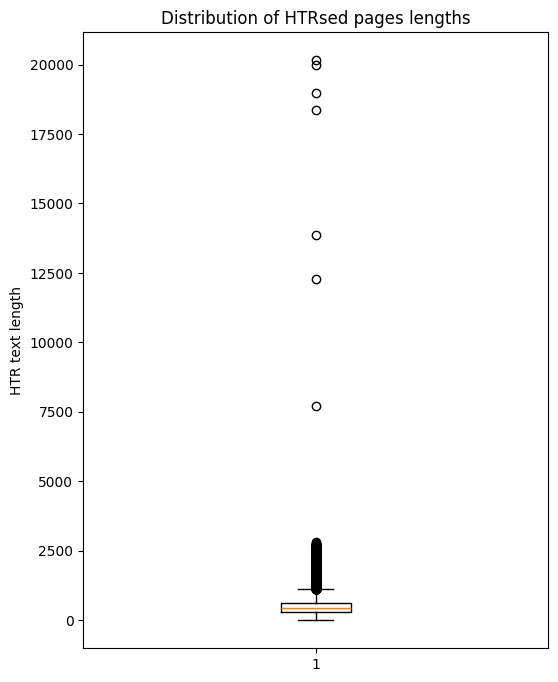

In [108]:
plt.figure(figsize=(6, 8))

plt.boxplot(
    pages_length_df["HTR_text_length"].dropna(),
    vert=True
)

plt.ylabel("HTR text length")
plt.title("Distribution of HTRsed pages lengths")

plt.show()

NB : France, Paris, Bibliothèque nationale de France, Manuscrits, [lat. 14284](https://demo.arkindex.org/element/b0a54612-a0fd-48c9-b413-6b8072093827?from=5d8fd1ad-2d65-4aa8-8938-f4d757b2c840) contains 12 pages (7 images, 71r-76v) of "Sentences" by Pierre Lombard, written in 2 columns, in closely spaced lettering, i.e. pages de 20 000 characters are not an error

## 2.3. Collect the annotations

4 de ces manuscrits ont l'annotation structurelle. <br>
51 de de ces mss sont annotés par Leroquais. <br>
163 de ces mss ont l'annotation partielle au niveau des textes.  <br>
La liste: "04.CoMMa\\02.metadata\\196_arkindex_Comma_URL_filled.csv"

In [109]:
leroquais_mss_df = pd.read_csv("04.CoMMa\\02.metadata\\196_arkindex_Comma_URL_filled.csv")
leroquais_mss_df = leroquais_mss_df[leroquais_mss_df["Leroquais_annotation"] == True]
leroquais_mss_df = leroquais_mss_df[leroquais_mss_df["arkindex_comma_aligned"] == True]
leroquais_mss_df.drop(columns=["Leroquais_annotation", "arkindex_comma_aligned"], inplace=True, errors="ignore")
leroquais_mss_df


,Manuscript H-ID,bbma_data_entity,ID Arkindex,URL CoMMA,Structural annotation,partially annotated
11,2380,https://data.biblissima.fr/entity/Q58836,82c6c1e4-ac24-4b3b-ab78-c795c2f3fd66,https://comma.inria.fr/doc/https%253A%252F%252...,False,False
12,2384,https://data.biblissima.fr/entity/Q109594,a7bb2ecc-e89c-4805-8378-8dc8163cb582,https://comma.inria.fr/doc/https%253A%252F%252...,False,True
15,2390,https://data.biblissima.fr/entity/Q109588,d1cda616-216c-4cc2-b796-f3b00deaac67,https://comma.inria.fr/doc/https%253A%252F%252...,False,True
16,2392,https://data.biblissima.fr/entity/Q109592,09878703-855a-425e-a0fd-239b83a81de5,https://comma.inria.fr/doc/https%253A%252F%252...,False,True
17,2393,https://data.biblissima.fr/entity/Q59226,f8ac87c1-b602-4093-8bde-419bf7a38c3d,https://comma.inria.fr/doc/https%253A%252F%252...,False,True
18,2398,https://data.biblissima.fr/entity/Q59252,2e5fd8a1-1f44-456b-b3e3-8fc147ba70dc,https://comma.inria.fr/doc/https%253A%252F%252...,False,True
19,2405,https://data.biblissima.fr/entity/Q59285,9b368755-771a-4457-9ee8-332e548b3e57,https://comma.inria.fr/doc/https%253A%252F%252...,False,True
20,2409,https://data.biblissima.fr/entity/Q59293,9fb79d58-9c62-49eb-896f-a61ddcccd9e7,https://comma.inria.fr/doc/https%253A%252F%252...,False,True
21,2412,https://data.biblissima.fr/entity/Q109600,8ec3994a-ab25-497e-bb0e-ede0c47d763a,https://comma.inria.fr/doc/https%253A%252F%252...,False,True
23,2418,https://data.biblissima.fr/entity/Q59330,27a9ff14-517c-45cb-a233-c52d62038399,https://comma.inria.fr/doc/https%253A%252F%252...,False,True


### 2.3.1. Fetch Leroquais' annotations for 51 mss

In [110]:
annotated_mss_df = pd.read_csv('01.data\\03.Leroquais\\07.annotations_for_evaluation\\psalter_gospels_prayers.csv', sep="\t")
annotated_mss_df

,ms_arkindex_id,Manuscript H-ID,Work H-ID,rec_Title,page_ordering_beginning,arkindex_page_id_beginning,page_ordering_ending,arkindex_page_id_ending,annotated_text_h_id
0,0253a5a1-0667-4c1c-b499-a59d48abc884,2681,708963,Psalter | L1 | Section,3,41c69405-4483-4bf4-810d-dbccb3ec7bc9,191,b0a95de3-cae4-4054-8630-e5082609eb48,"395790,399439,398201,396635,395319,398179,3979..."
1,0253a5a1-0667-4c1c-b499-a59d48abc884,2681,394830,Penitential Psalms | L2 | Section,253,07714b7a-86d2-4953-b03b-f7ec35e595d2,262,157f44ba-22c3-46b8-8c05-dfb62cb6e9c1,"398179,395746,398168,399184,398146,396857,398134"
2,0253a5a1-0667-4c1c-b499-a59d48abc884,2681,394797,O intemerata | L1 | Section,280,5ac707e7-3f18-4bed-8467-78d7b4f84d97,280,5ac707e7-3f18-4bed-8467-78d7b4f84d97,399249
3,05306f49-5c9a-466c-9d5a-e99461c52438,2589,394830,Penitential Psalms | L2 | Section,267,96f371b6-4d3c-453d-b28d-1cb4a103cf22,287,ac687215-a32c-41c2-8299-36a66892fa56,"398179,395746,398168,399184,398146,396857,398134"
4,094b5d7a-c512-4290-924c-81b48dea2fd9,2524,394830,Penitential Psalms | L2 | Section,134,cbc3696e-56f2-4f4c-b3cb-0190b5ed95ac,159,daa5f87a-dfcc-4b8f-b53a-1893f6c216ea,"398179,395746,398168,399184,398146,396857,398134"
...,...,...,...,...,...,...,...,...,...
174,f8ac87c1-b602-4093-8bde-419bf7a38c3d,2393,394830,Penitential Psalms | L2 | Section,161,db40f729-3f45-4cc1-9476-d09d817fba38,183,52e9112c-7d4d-4cfc-bfcb-06141f5f6064,"398179,395746,398168,399184,398146,396857,398134"
175,f9f1fca3-072f-4056-9144-8aae1d4a6504,2470,394830,Penitential Psalms | L2 | Section,133,cf193540-251e-42be-aead-9f7defea24e8,151,1d267be8-caa5-4aee-9404-265374c61b15,"398179,395746,398168,399184,398146,396857,398134"
176,fe53336d-eb9f-46a8-971a-ef1c63e9be58,2622,394830,Penitential Psalms | L2 | Section,113,719940b5-bc57-4c88-8e2d-b1afbc8ccf32,125,a31c3362-21fe-45c7-ba64-dad1619d96bf,"398179,395746,398168,399184,398146,396857,398134"
177,fe53336d-eb9f-46a8-971a-ef1c63e9be58,2622,394797,O intemerata | L1 | Section,249,3c3201fb-0fe2-407f-a10a-3763f97bd2e6,251,c1ebe4dc-3ff5-4ef2-afe1-b52f70290012,399249


In [111]:
# add text length

ref_length_map = (
    ref_texts_length_df
    .assign(ref_text_id=ref_texts_length_df["ref_text_id"].astype(str).str.strip())
    .set_index("ref_text_id")["text_length"]
)

ids = annotated_mss_df["annotated_text_h_id"].astype(str).str.strip()

annotated_mss_df["text_length"] = (
    ids.where(~ids.str.contains(",", na=False))
      .map(ref_length_map)
      .astype("Int64")
)

annotated_mss_df["page_ordering_ending"] = (
    annotated_mss_df["page_ordering_ending"].astype("Int64")
)

annotated_mss_df

,ms_arkindex_id,Manuscript H-ID,Work H-ID,rec_Title,page_ordering_beginning,arkindex_page_id_beginning,page_ordering_ending,arkindex_page_id_ending,annotated_text_h_id,text_length
0,0253a5a1-0667-4c1c-b499-a59d48abc884,2681,708963,Psalter | L1 | Section,3,41c69405-4483-4bf4-810d-dbccb3ec7bc9,191,b0a95de3-cae4-4054-8630-e5082609eb48,"395790,399439,398201,396635,395319,398179,3979...",<NA>
1,0253a5a1-0667-4c1c-b499-a59d48abc884,2681,394830,Penitential Psalms | L2 | Section,253,07714b7a-86d2-4953-b03b-f7ec35e595d2,262,157f44ba-22c3-46b8-8c05-dfb62cb6e9c1,"398179,395746,398168,399184,398146,396857,398134",<NA>
2,0253a5a1-0667-4c1c-b499-a59d48abc884,2681,394797,O intemerata | L1 | Section,280,5ac707e7-3f18-4bed-8467-78d7b4f84d97,280,5ac707e7-3f18-4bed-8467-78d7b4f84d97,399249,2329
3,05306f49-5c9a-466c-9d5a-e99461c52438,2589,394830,Penitential Psalms | L2 | Section,267,96f371b6-4d3c-453d-b28d-1cb4a103cf22,287,ac687215-a32c-41c2-8299-36a66892fa56,"398179,395746,398168,399184,398146,396857,398134",<NA>
4,094b5d7a-c512-4290-924c-81b48dea2fd9,2524,394830,Penitential Psalms | L2 | Section,134,cbc3696e-56f2-4f4c-b3cb-0190b5ed95ac,159,daa5f87a-dfcc-4b8f-b53a-1893f6c216ea,"398179,395746,398168,399184,398146,396857,398134",<NA>
...,...,...,...,...,...,...,...,...,...,...
174,f8ac87c1-b602-4093-8bde-419bf7a38c3d,2393,394830,Penitential Psalms | L2 | Section,161,db40f729-3f45-4cc1-9476-d09d817fba38,183,52e9112c-7d4d-4cfc-bfcb-06141f5f6064,"398179,395746,398168,399184,398146,396857,398134",<NA>
175,f9f1fca3-072f-4056-9144-8aae1d4a6504,2470,394830,Penitential Psalms | L2 | Section,133,cf193540-251e-42be-aead-9f7defea24e8,151,1d267be8-caa5-4aee-9404-265374c61b15,"398179,395746,398168,399184,398146,396857,398134",<NA>
176,fe53336d-eb9f-46a8-971a-ef1c63e9be58,2622,394830,Penitential Psalms | L2 | Section,113,719940b5-bc57-4c88-8e2d-b1afbc8ccf32,125,a31c3362-21fe-45c7-ba64-dad1619d96bf,"398179,395746,398168,399184,398146,396857,398134",<NA>
177,fe53336d-eb9f-46a8-971a-ef1c63e9be58,2622,394797,O intemerata | L1 | Section,249,3c3201fb-0fe2-407f-a10a-3763f97bd2e6,251,c1ebe4dc-3ff5-4ef2-afe1-b52f70290012,399249,2329


## 2.4. Collect, import and clean passim's predictions

### 2.4.1. Split pre-cleaned jsons in 2 folders </br>
- src series == source
- src series != source

In [112]:
input_dir = Path(r"04.CoMMa\00.data\04.passim_output\01.brut")
output_base = Path(r"04.CoMMa\00.data\04.passim_output\02.cleaned_json")

source_is_ref_dir = output_base / "source_is_ref"
source_is_page_dir = output_base / "source_is_page"
mixed_source_type_dir = output_base / "mixed_source_type"

for folder in [source_is_ref_dir, source_is_page_dir, mixed_source_type_dir]:
    folder.mkdir(parents=True, exist_ok=True)

ndjson_files = list(input_dir.rglob("merged.ndjson"))

for ndjson_file in tqdm(ndjson_files, desc="Processing NDJSON files"):

    data = []

    with open(ndjson_file, "r", encoding="utf-8") as f:
        for line_number, line in enumerate(f, start=1):
            line = line.strip()

            if not line:
                continue

            try:
                data.append(json.loads(line))
            except json.JSONDecodeError as e:
                print(f"❌ JSON error in {ndjson_file}, line {line_number}: {e}")

    if not data:
        print(f"⚠️ Empty or unreadable file: {ndjson_file}")
        continue

    clusters = defaultdict(list)

    for item in data:
        cluster_id = item.get("cluster")
        clusters[cluster_id].append(item)

    source_types = set()

    for cluster_items in clusters.values():

        source_series = {
            item.get("series")
            for item in cluster_items
            if isinstance(item.get("src"), list) and item.get("src")
        }

        if "source" in source_series:
            source_types.add("source_is_page")
        else:
            source_types.add("source_is_ref")

        if source_types == {"source_is_ref"}:
            target_dir = source_is_ref_dir
        elif source_types == {"source_is_page"}:
            target_dir = source_is_page_dir
        else:
            target_dir = mixed_source_type_dir

        output_name = f"{ndjson_file.parent.name}.json"

        with open(target_dir / output_name, "w", encoding="utf-8") as out_f:
            json.dump(
                data,
                out_f,
                ensure_ascii=False,
                indent=2
            )

print("\nAll done! Files are distributed as follows:")
print(f"Reference 'series' == 'source': {len(list(source_is_ref_dir.glob('*.json')))} files")
print(f"Reference 'series' != 'source': {len(list(source_is_page_dir.glob('*.json')))} files")
print(f"⚠️ Mixed clusters: {len(list(mixed_source_type_dir.glob('*.json')))} files")

Processing NDJSON files: 100%|██████████| 176/176 [08:41<00:00,  2.97s/it]


All done! Files are distributed as follows:
Reference 'series' == 'source': 28 files
Reference 'series' != 'source': 148 files
⚠️ Mixed clusters: 0 files


### 2.4.2. Transform passim's predictions from json to dataframe

In [113]:
base_dir="04.CoMMa\\00.data\\04.passim_output\\02.cleaned_json"
ref_path = "01.data\\01.text_editions\\texts_from_Heurist\\ref_all_texts.csv"

#### 2.4.2.1. Extract the data

In [114]:
combined_df = load_combined_passim_predictions(
    base_dir=base_dir,
    ref_texts_length_df=ref_texts_length_df,
    pages_length_df=pages_length_df,
    ref_path = ref_path
)

# add text length
combined_df['text_length'] = combined_df['source_text_id'].map(
    ref_texts_length_df.set_index('ref_text_id')['text_length']
)

combined_df

# 44 804 rows -- 21 secs

,source_text_id,page_ordering,ms_arkindex_id,text_match_begin_offset,text_match_end_offset,page_match_begin_offset,page_match_end_offset,Nature,source_dataset,parameters,text_length
0,707071,90,0b216ba3-7491-412c-abe8-b07ec4dad742,341,463,138,261,original prediction,passim,n10_a100_m5_df2-100_g600,682
1,399048,75,0b216ba3-7491-412c-abe8-b07ec4dad742,421,891,0,463,original prediction,passim,n10_a100_m5_df2-100_g600,997
2,399048,74,0b216ba3-7491-412c-abe8-b07ec4dad742,1,419,89,500,original prediction,passim,n10_a100_m5_df2-100_g600,997
3,399278,85,0b216ba3-7491-412c-abe8-b07ec4dad742,5,361,98,432,original prediction,passim,n10_a100_m5_df2-100_g600,3321
4,399278,137,0b216ba3-7491-412c-abe8-b07ec4dad742,1,399,0,386,original prediction,passim,n10_a100_m5_df2-100_g600,3321
...,...,...,...,...,...,...,...,...,...,...,...
25680,396079,123,ff5abf5d-527f-4db5-9ae0-51222fe71a78,43,490,0,431,original prediction,passim,n10_a100_m5_df2-100_g600,623
25681,396068,97,ff5abf5d-527f-4db5-9ae0-51222fe71a78,58,540,0,441,original prediction,passim,n10_a100_m5_df2-100_g600,1053
25682,396079,261,ff5abf5d-527f-4db5-9ae0-51222fe71a78,0,623,0,257,original prediction,passim,n10_a100_m5_df2-100_g600,623
25683,396079,260,ff5abf5d-527f-4db5-9ae0-51222fe71a78,0,355,102,436,original prediction,passim,n10_a100_m5_df2-100_g600,623


In [115]:
# calculate unique ms ids
combined_df["ms_arkindex_id"].nunique()

173

For some reason, only 173 of the 176 mss get into the df. Let's investigate why

#### 2.4.2.2. List files with no extracted rows

In [116]:
base_path = Path(base_dir)

file_stats = []

for subfolder, extractor in {
    "source_is_ref": create_dataframe_from_json_source_is_ref,
    "source_is_page": create_dataframe_from_json_source_is_page,
}.items():
    for json_file in (base_path / subfolder).glob("*.json"):
        df = extractor(
            json_filepath=str(json_file),
            ref_texts_length_df=ref_texts_length_df,
            pages_length_df=pages_length_df,
            ref_path=ref_path
        )

        file_stats.append({
            "subfolder": subfolder,
            "json_file": json_file.name,
            "rows_after_extraction": len(df),
            "ms_arkindex_ids": sorted(df["ms_arkindex_id"].dropna().unique()) if not df.empty else []
        })

file_stats_df = pd.DataFrame(file_stats)

empty_files = file_stats_df[file_stats_df["rows_after_extraction"] == 0]

empty_files

,subfolder,json_file,rows_after_extraction,ms_arkindex_ids
12,source_is_ref,8b860405-c988-4e4c-975a-5246a6c0dae8_n10_a100_...,0,[]
35,source_is_page,05906f2e-0c51-472d-a1f6-b8d59502057b_n10_a100_...,0,[]
140,source_is_page,c855a644-405f-4262-bc24-73565c447135_n10_a100_...,0,[]


#### 2.4.2.3. Print clusters and work H-IDs

In [117]:
for _, row in empty_files.iterrows():
    json_file = base_path / row["subfolder"] / row["json_file"]

    with open(json_file, "r", encoding="utf-8") as f:
        data = json.load(f)

    print("\n", json_file)
    print("items:", len(data))
    print("series:", Counter(item.get("series") for item in data))
    print("clusters:", len(set(item.get("cluster") for item in data)))
    print("source ids:", sorted({
        item.get("id")
        for item in data
        if item.get("series") == "source"
    })[:20])


 04.CoMMa\00.data\04.passim_output\02.cleaned_json\source_is_ref\8b860405-c988-4e4c-975a-5246a6c0dae8_n10_a100_m5_df2-100_g600.json
items: 12
series: Counter({'source': 6, '8b860405-c988-4e4c-975a-5246a6c0dae8': 6})
clusters: 6
source ids: [396591, 398998, 712866, 712886, 713504, 713720]

 04.CoMMa\00.data\04.passim_output\02.cleaned_json\source_is_page\05906f2e-0c51-472d-a1f6-b8d59502057b_n10_a100_m5_df2-100_g600.json
items: 10
series: Counter({'05906f2e-0c51-472d-a1f6-b8d59502057b': 5, 'source': 5})
clusters: 5
source ids: [712207, 712775, 713004, 713821]

 04.CoMMa\00.data\04.passim_output\02.cleaned_json\source_is_page\c855a644-405f-4262-bc24-73565c447135_n10_a100_m5_df2-100_g600.json
items: 4
series: Counter({'c855a644-405f-4262-bc24-73565c447135': 2, 'source': 2})
clusters: 2
source ids: [713004, 713821]


These manuscripts don't contain any of 179 texts extracted from Leroquais.

#### 2.4.2.4. Sanity check: are all extracted mss annotated by Leroquais ?

In [118]:
# Unique IDs for Leroquais and for passim
leroquais_ids = set(leroquais_mss_df["ID Arkindex"].dropna().astype(str).unique())
combined_ids = set(combined_df["ms_arkindex_id"].dropna().astype(str).unique())

intersection_ids = leroquais_ids.intersection(combined_ids)

# Unique mss ids for Leroquais
only_in_leroquais = sorted(leroquais_ids - combined_ids)

print(f"Unique IDs in leroquais_mss_df: {len(leroquais_ids)}")
print(f"Unique IDs in combined_df: {len(combined_ids)}")
print(f"Intersection count: {len(intersection_ids)}")
print(f"Only in leroquais_mss_df: {len(only_in_leroquais)}")

print("\nIDs only in leroquais_mss_df:")
for ms_id in only_in_leroquais:
    print(ms_id)

Unique IDs in leroquais_mss_df: 51
Unique IDs in combined_df: 173
Intersection count: 51
Only in leroquais_mss_df: 0

IDs only in leroquais_mss_df:


In [119]:
# keep only mss annotated by Leroquais
ms_ids = set(leroquais_mss_df['ID Arkindex'].astype(str))
before = len(combined_df)
combined_df = combined_df[combined_df['ms_arkindex_id'].astype(str).isin(ms_ids)].reset_index(drop=True)
after = len(combined_df)
print(f"Filtered combined_df: {before} -> {after} rows.")

combined_df

Filtered combined_df: 25685 -> 7854 rows.


,source_text_id,page_ordering,ms_arkindex_id,text_match_begin_offset,text_match_end_offset,page_match_begin_offset,page_match_end_offset,Nature,source_dataset,parameters,text_length
0,399048,14,27a9ff14-517c-45cb-a233-c52d62038399,107,997,0,878,original prediction,passim,n10_a100_m5_df2-100_g600,997
1,399048,13,27a9ff14-517c-45cb-a233-c52d62038399,1,103,896,1008,original prediction,passim,n10_a100_m5_df2-100_g600,997
2,399249,22,27a9ff14-517c-45cb-a233-c52d62038399,1114,1550,0,429,original prediction,passim,n10_a100_m5_df2-100_g600,2329
3,399249,22,27a9ff14-517c-45cb-a233-c52d62038399,1547,2214,428,1042,original prediction,passim,n10_a100_m5_df2-100_g600,2329
4,399249,21,27a9ff14-517c-45cb-a233-c52d62038399,1,1114,36,1059,original prediction,passim,n10_a100_m5_df2-100_g600,2329
...,...,...,...,...,...,...,...,...,...,...,...
7849,395746,136,f9f1fca3-072f-4056-9144-8aae1d4a6504,0,1060,0,438,original prediction,passim,n10_a100_m5_df2-100_g600,1061
7850,396035,61,f9f1fca3-072f-4056-9144-8aae1d4a6504,0,397,57,432,original prediction,passim,n10_a100_m5_df2-100_g600,1222
7851,396035,62,f9f1fca3-072f-4056-9144-8aae1d4a6504,0,922,0,489,original prediction,passim,n10_a100_m5_df2-100_g600,1222
7852,396035,63,f9f1fca3-072f-4056-9144-8aae1d4a6504,912,1221,0,297,original prediction,passim,n10_a100_m5_df2-100_g600,1222


### 2.4.3. Delete the duplicates from passim's predictions

In [120]:
'''Detect these duplicates.'''

subset_cols = ['ms_arkindex_id', 'page_ordering', 'source_text_id', 'parameters']

dup_mask = combined_df.duplicated(subset=subset_cols, keep=False)

n_unique_duplicates = combined_df.loc[dup_mask, subset_cols].drop_duplicates().shape[0]

# Add a column for repetitions
combined_df['double'] = np.where(dup_mask, 'double', '')
print(f"Found {dup_mask.sum()} duplicates in total.")
print(f"Unique combinations amongst them: {n_unique_duplicates}")

combined_df

Found 400 duplicates in total.
Unique combinations amongst them: 197


,source_text_id,page_ordering,ms_arkindex_id,text_match_begin_offset,text_match_end_offset,page_match_begin_offset,page_match_end_offset,Nature,source_dataset,parameters,text_length,double
0,399048,14,27a9ff14-517c-45cb-a233-c52d62038399,107,997,0,878,original prediction,passim,n10_a100_m5_df2-100_g600,997,
1,399048,13,27a9ff14-517c-45cb-a233-c52d62038399,1,103,896,1008,original prediction,passim,n10_a100_m5_df2-100_g600,997,
2,399249,22,27a9ff14-517c-45cb-a233-c52d62038399,1114,1550,0,429,original prediction,passim,n10_a100_m5_df2-100_g600,2329,double
3,399249,22,27a9ff14-517c-45cb-a233-c52d62038399,1547,2214,428,1042,original prediction,passim,n10_a100_m5_df2-100_g600,2329,double
4,399249,21,27a9ff14-517c-45cb-a233-c52d62038399,1,1114,36,1059,original prediction,passim,n10_a100_m5_df2-100_g600,2329,
...,...,...,...,...,...,...,...,...,...,...,...,...
7849,395746,136,f9f1fca3-072f-4056-9144-8aae1d4a6504,0,1060,0,438,original prediction,passim,n10_a100_m5_df2-100_g600,1061,
7850,396035,61,f9f1fca3-072f-4056-9144-8aae1d4a6504,0,397,57,432,original prediction,passim,n10_a100_m5_df2-100_g600,1222,
7851,396035,62,f9f1fca3-072f-4056-9144-8aae1d4a6504,0,922,0,489,original prediction,passim,n10_a100_m5_df2-100_g600,1222,
7852,396035,63,f9f1fca3-072f-4056-9144-8aae1d4a6504,912,1221,0,297,original prediction,passim,n10_a100_m5_df2-100_g600,1222,


In [121]:
'''Delete the duplicates.'''

combined_no_doubles_df = combined_df.drop_duplicates(
    subset=['ms_arkindex_id', 'page_ordering', 'source_text_id', 'parameters'],
    keep='first'
)

combined_no_doubles_df = combined_no_doubles_df.drop(columns=['double'], errors='ignore')

combined_no_doubles_df

,source_text_id,page_ordering,ms_arkindex_id,text_match_begin_offset,text_match_end_offset,page_match_begin_offset,page_match_end_offset,Nature,source_dataset,parameters,text_length
0,399048,14,27a9ff14-517c-45cb-a233-c52d62038399,107,997,0,878,original prediction,passim,n10_a100_m5_df2-100_g600,997
1,399048,13,27a9ff14-517c-45cb-a233-c52d62038399,1,103,896,1008,original prediction,passim,n10_a100_m5_df2-100_g600,997
2,399249,22,27a9ff14-517c-45cb-a233-c52d62038399,1114,1550,0,429,original prediction,passim,n10_a100_m5_df2-100_g600,2329
4,399249,21,27a9ff14-517c-45cb-a233-c52d62038399,1,1114,36,1059,original prediction,passim,n10_a100_m5_df2-100_g600,2329
5,399278,18,27a9ff14-517c-45cb-a233-c52d62038399,1,355,0,299,original prediction,passim,n10_a100_m5_df2-100_g600,3321
...,...,...,...,...,...,...,...,...,...,...,...
7849,395746,136,f9f1fca3-072f-4056-9144-8aae1d4a6504,0,1060,0,438,original prediction,passim,n10_a100_m5_df2-100_g600,1061
7850,396035,61,f9f1fca3-072f-4056-9144-8aae1d4a6504,0,397,57,432,original prediction,passim,n10_a100_m5_df2-100_g600,1222
7851,396035,62,f9f1fca3-072f-4056-9144-8aae1d4a6504,0,922,0,489,original prediction,passim,n10_a100_m5_df2-100_g600,1222
7852,396035,63,f9f1fca3-072f-4056-9144-8aae1d4a6504,912,1221,0,297,original prediction,passim,n10_a100_m5_df2-100_g600,1222


### 2.4.4. Make sure we only keep 179 texts extracted from Leroquais' annotations

In [122]:
valid_ref_ids = set(ref_texts_length_df["ref_text_id"])
combined_filtered_df = combined_no_doubles_df[
    combined_no_doubles_df["source_text_id"].isin(valid_ref_ids)
].reset_index(drop=True)

combined_filtered_df

,source_text_id,page_ordering,ms_arkindex_id,text_match_begin_offset,text_match_end_offset,page_match_begin_offset,page_match_end_offset,Nature,source_dataset,parameters,text_length
0,399048,14,27a9ff14-517c-45cb-a233-c52d62038399,107,997,0,878,original prediction,passim,n10_a100_m5_df2-100_g600,997
1,399048,13,27a9ff14-517c-45cb-a233-c52d62038399,1,103,896,1008,original prediction,passim,n10_a100_m5_df2-100_g600,997
2,399249,22,27a9ff14-517c-45cb-a233-c52d62038399,1114,1550,0,429,original prediction,passim,n10_a100_m5_df2-100_g600,2329
3,399249,21,27a9ff14-517c-45cb-a233-c52d62038399,1,1114,36,1059,original prediction,passim,n10_a100_m5_df2-100_g600,2329
4,399278,18,27a9ff14-517c-45cb-a233-c52d62038399,1,355,0,299,original prediction,passim,n10_a100_m5_df2-100_g600,3321
...,...,...,...,...,...,...,...,...,...,...,...
7646,395746,136,f9f1fca3-072f-4056-9144-8aae1d4a6504,0,1060,0,438,original prediction,passim,n10_a100_m5_df2-100_g600,1061
7647,396035,61,f9f1fca3-072f-4056-9144-8aae1d4a6504,0,397,57,432,original prediction,passim,n10_a100_m5_df2-100_g600,1222
7648,396035,62,f9f1fca3-072f-4056-9144-8aae1d4a6504,0,922,0,489,original prediction,passim,n10_a100_m5_df2-100_g600,1222
7649,396035,63,f9f1fca3-072f-4056-9144-8aae1d4a6504,912,1221,0,297,original prediction,passim,n10_a100_m5_df2-100_g600,1222


### 2.4.5. Save the df

In [123]:
combined_filtered_df.to_csv(
    "04.CoMMa\\02.metadata\\00.passim_evaluation\\51MSS_179texts_optimal_params_pure_passim_prediction_no_doubles_isolated_preds_not_deleted.csv",
    index=False,
    encoding="utf-8"
)

## 2.5. Merge annotated data with passim's predictions

In [124]:
#normalise column names

from_passim_df = pd.DataFrame({
    'ms_arkindex_id': combined_filtered_df['ms_arkindex_id'],
    'page_ordering_beginning': combined_filtered_df['page_ordering'],
    'source_dataset': combined_filtered_df['source_dataset'],
    'source_text_id': combined_filtered_df['source_text_id'],
    'Nature': combined_filtered_df['Nature'],
    'parameters': combined_filtered_df['parameters'],
    'text_length': combined_filtered_df['text_length']
})

from_annotated_df = pd.DataFrame({
    'ms_arkindex_id': annotated_mss_df['ms_arkindex_id'],
    'page_ordering_beginning': annotated_mss_df['page_ordering_beginning'],
    'page_ordering_ending': annotated_mss_df['page_ordering_ending'],
    'source_dataset': 'Annotation',
    'source_text_id': annotated_mss_df['annotated_text_h_id'],
    'text_length': annotated_mss_df['text_length']
})

In [125]:
# Only keep annotations for manuscripts treated by passim
mss_treated_by_passim_df = from_annotated_df[
    from_annotated_df["ms_arkindex_id"].isin(from_passim_df["ms_arkindex_id"])
].copy()

# Add missing columns to annotations
for col in from_passim_df.columns:
    if col not in mss_treated_by_passim_df.columns:
        mss_treated_by_passim_df[col] = np.nan

# Add missing columns to passim predictions
for col in mss_treated_by_passim_df.columns:
    if col not in from_passim_df.columns:
        from_passim_df[col] = np.nan

# Use the same column order
mss_treated_by_passim_df = mss_treated_by_passim_df[from_passim_df.columns]

# Concatenate passim predictions with annotations
annot_df = pd.concat(
    [from_passim_df, mss_treated_by_passim_df],
    ignore_index=True
)

# Convert float columns to nullable integers when possible
for col in annot_df.select_dtypes(include="float").columns:
    if annot_df[col].dropna().apply(float.is_integer).all():
        annot_df[col] = annot_df[col].astype("Int64")

annot_df

C:\Users\Mohamed\AppData\Local\Temp\ipykernel_1228\1478971684.py:20: FutureWarning:

The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.



,ms_arkindex_id,page_ordering_beginning,source_dataset,source_text_id,Nature,parameters,text_length,page_ordering_ending
0,27a9ff14-517c-45cb-a233-c52d62038399,14,passim,399048,original prediction,n10_a100_m5_df2-100_g600,997,<NA>
1,27a9ff14-517c-45cb-a233-c52d62038399,13,passim,399048,original prediction,n10_a100_m5_df2-100_g600,997,<NA>
2,27a9ff14-517c-45cb-a233-c52d62038399,22,passim,399249,original prediction,n10_a100_m5_df2-100_g600,2329,<NA>
3,27a9ff14-517c-45cb-a233-c52d62038399,21,passim,399249,original prediction,n10_a100_m5_df2-100_g600,2329,<NA>
4,27a9ff14-517c-45cb-a233-c52d62038399,18,passim,399278,original prediction,n10_a100_m5_df2-100_g600,3321,<NA>
...,...,...,...,...,...,...,...,...
7798,f411cb6b-7e69-4e08-bdc8-282b62469daa,265,Annotation,"398179,395746,398168,399184,398146,396857,398134",NaN,NaN,<NA>,289
7799,f8ac87c1-b602-4093-8bde-419bf7a38c3d,37,Annotation,"398801,399048,399412,399186,396679,395086",NaN,NaN,<NA>,43
7800,f8ac87c1-b602-4093-8bde-419bf7a38c3d,43,Annotation,399278,NaN,NaN,3321,51
7801,f8ac87c1-b602-4093-8bde-419bf7a38c3d,161,Annotation,"398179,395746,398168,399184,398146,396857,398134",NaN,NaN,<NA>,183


## 2.6. Save it

In [126]:
annot_df.to_csv("04.CoMMa\\02.metadata\\00.passim_evaluation\\51MSS_179texts_optimal_params_pure_passim_prediction_no_doubles_with_annotations.csv", index=False, encoding="utf-8")               

In [6]:
annot_df = pd.read_csv("04.CoMMa\\02.metadata\\00.passim_evaluation\\51MSS_179texts_optimal_params_pure_passim_prediction_no_doubles_with_annotations.csv")

# 3. passim prediction evaluation

## 3.1. Helper functions

In [64]:
def normalize_source_text_ids(value):
    if pd.isna(value):
        return set()
    return {
        item.strip()
        for item in str(value).split(',')
        if item.strip()
    }

### 3.1.1. Evaluate each passim's prediction

In [65]:
def evaluate_passim_prediction(df):
    """
    For every row from passim predictions, check if there is an annotation
    for the same manuscript that covers the predicted page and contains
    the same source_text_id.

    Passim rows get:
        - status = True positive / False positive
        - matched_annotation_index = index of matched Annotation row, or pd.NA

    Annotation rows get:
        - status = pd.NA
        - matched_annotation_index = pd.NA
    """

    df = df.copy()

    df["page_ordering_beginning"] = pd.to_numeric(
        df["page_ordering_beginning"], errors="coerce"
    )
    df["page_ordering_ending"] = pd.to_numeric(
        df["page_ordering_ending"], errors="coerce"
    )

    annotations_df = df[df["source_dataset"] == "Annotation"].copy()

    annotations_df["_source_text_ids"] = annotations_df["source_text_id"].apply(
        normalize_source_text_ids
    )

    def compute_match(row):
        if row["source_dataset"] != "passim":
            return pd.Series({
                "status": pd.NA,
                "matched_annotation_index": pd.NA,
            })

        page_ordering = pd.to_numeric(row["page_ordering_beginning"], errors="coerce")

        if pd.isna(page_ordering):
            return pd.Series({
                "status": "False positive",
                "matched_annotation_index": pd.NA,
            })

        source_text_id = str(row["source_text_id"]).strip()

        matches = annotations_df[
            (annotations_df["ms_arkindex_id"] == row["ms_arkindex_id"])
            & (annotations_df["page_ordering_beginning"] <= page_ordering)
            & (annotations_df["page_ordering_ending"] >= page_ordering)
        ]

        matches = matches[
            matches["_source_text_ids"].apply(lambda ids: source_text_id in ids)
        ]

        if len(matches):
            return pd.Series({
                "status": "True positive",
                "matched_annotation_index": matches.index[0],
            })

        return pd.Series({
            "status": "False positive",
            "matched_annotation_index": pd.NA,
        })

    df[["status", "matched_annotation_index"]] = df.apply(compute_match, axis=1)

    return df

### 3.1.2. Calculate precision

In [66]:
def calculate_passim_precision(df, group_col='parameters'):
    """
    Precision = True positives / Total predictions

    By default, it calculates precision for each unique parameter in "parameters" column.
    If group_col is None, it calculates overall precision.
    """

    passim_df = df[df['source_dataset'] == 'passim'].copy()

    if group_col is None:
        total_predictions = len(passim_df)
        true_positives = (passim_df['status'] == 'True positive').sum()
        precision = true_positives / total_predictions if total_predictions else np.nan
        return pd.DataFrame({
            'total_predictions': [total_predictions],
            'true_positives': [true_positives],
            'precision': [precision]
        })

    precision_df = (
        passim_df.groupby(group_col, dropna=False)
        .agg(
            total_predictions=('status', 'size'),
            true_positives=('status', lambda s: (s == 'True positive').sum())
        )
        .reset_index()
    )
    precision_df['precision'] = (
        precision_df['true_positives'] / precision_df['total_predictions']
    )
    return precision_df.sort_values('precision', ascending=False).reset_index(drop=True)


### 3.1.3. Calculate recall

In [67]:
def calculate_passim_recall(df, group_col="parameters"):
    """
    Recall = unique found annotations / total annotations.
    """

    annotations_df = df[df["source_dataset"] == "Annotation"].copy()
    passim_df = df[df["source_dataset"] == "passim"].copy()

    total_annotations = len(annotations_df)

    if group_col is None:
        found_annotations = (
            passim_df.loc[
                passim_df["status"] == "True positive",
                "matched_annotation_index"
            ]
            .dropna()
            .nunique()
        )

        recall = found_annotations / total_annotations if total_annotations else np.nan

        return pd.DataFrame({
            "total_annotations": [total_annotations],
            "found_annotations": [found_annotations],
            "recall": [recall],
        })

    recall_df = (
        passim_df[passim_df["status"] == "True positive"]
        .groupby(group_col, dropna=False)
        .agg(
            found_annotations=("matched_annotation_index", lambda s: s.dropna().nunique())
        )
        .reset_index()
    )

    recall_df["total_annotations"] = total_annotations
    recall_df["recall"] = recall_df["found_annotations"] / recall_df["total_annotations"]

    return recall_df.sort_values("recall", ascending=False).reset_index(drop=True)

### 3.1.4. Coverage evaluation

In [68]:
def calculate_multiple_work_coverage(
    df,
    annotation_source_dataset="Annotation",
    passim_source_dataset="passim",
    group_col="parameters",
):
    df = df.copy()

    annotations_df = df[df["source_dataset"] == annotation_source_dataset].copy()
    passim_df = df[df["source_dataset"] == passim_source_dataset].copy()

    annotations_df["annotation_index"] = annotations_df.index

    annotations_df["_expected_source_text_ids"] = annotations_df["source_text_id"].apply(
        normalize_source_text_ids
    )

    annotations_df["total_expected_texts"] = annotations_df[
        "_expected_source_text_ids"
    ].apply(lambda ids: len(set(ids)))

    multiple_annotations_df = annotations_df[
        annotations_df["total_expected_texts"] > 1
    ].copy()

    true_positive_df = passim_df[
        passim_df["status"] == "True positive"
    ].copy()

    true_positive_df["matched_annotation_index"] = pd.to_numeric(
        true_positive_df["matched_annotation_index"],
        errors="coerce"
    )

    true_positive_df["_found_source_text_id"] = (
        true_positive_df["source_text_id"]
        .astype(str)
        .str.strip()
    )

    results = []

    if group_col is None:
        for annotation_index, annotation_row in multiple_annotations_df.iterrows():
            expected_ids = set(annotation_row["_expected_source_text_ids"])

            matching_passim_rows = true_positive_df[
                true_positive_df["matched_annotation_index"] == annotation_index
            ]

            found_ids = set(matching_passim_rows["_found_source_text_id"])
            found_ids = expected_ids & found_ids

            results.append({
                group_col: group_value,

                "annotation_index": annotation_index,

                "ms_arkindex_id": annotation_row["ms_arkindex_id"],
                "page_ordering_beginning": annotation_row["page_ordering_beginning"],
                "page_ordering_ending": annotation_row["page_ordering_ending"],

                "total_expected_texts": len(expected_ids),
                "found_texts": len(found_ids),
                "coverage": len(found_ids) / len(expected_ids) if expected_ids else np.nan,

                "expected_source_text_ids": ",".join(sorted(expected_ids)),
                "found_source_text_ids": ",".join(sorted(found_ids)),
                "missing_source_text_ids": ",".join(sorted(expected_ids - found_ids)),
            })

    else:
        parameter_values = passim_df[group_col].drop_duplicates().tolist()

        for annotation_index, annotation_row in multiple_annotations_df.iterrows():
            expected_ids = set(annotation_row["_expected_source_text_ids"])

            for group_value in parameter_values:
                matching_passim_rows = true_positive_df[
                    (true_positive_df["matched_annotation_index"] == annotation_index)
                    & (true_positive_df[group_col] == group_value)
                ]

                found_ids = set(matching_passim_rows["_found_source_text_id"])
                found_ids = expected_ids & found_ids

                results.append({
                    group_col: group_value,

                    "annotation_index": annotation_index,

                    "ms_arkindex_id": annotation_row["ms_arkindex_id"],
                    "page_ordering_beginning": annotation_row["page_ordering_beginning"],
                    "page_ordering_ending": annotation_row["page_ordering_ending"],

                    "total_expected_texts": len(expected_ids),
                    "found_texts": len(found_ids),
                    "coverage": len(found_ids) / len(expected_ids) if expected_ids else np.nan,

                    "expected_source_text_ids": ",".join(sorted(expected_ids)),
                    "found_source_text_ids": ",".join(sorted(found_ids)),
                    "missing_source_text_ids": ",".join(sorted(expected_ids - found_ids)),
                })

    coverage_df = pd.DataFrame(results)

    return coverage_df.sort_values(
        ["coverage", "found_texts"],
        ascending=[False, False]
    ).reset_index(drop=True)

### 3.1.5. Add work type to each composite annotation

In [69]:
def split_ids(value):
    if pd.isna(value) or value == "":
        return []
    return [x.strip() for x in str(value).split(",") if x.strip()]


psalter_ids = set(all_psalms["Work H-ID"].astype(str))
penitential_ids = set(penitential_psalms["Work H-ID"].astype(str))
gospel_lections_ids = set(gospel_lections["Work H-ID"].astype(str))


def detect_work_type(expected_ids):
    expected_ids = set(expected_ids)

    if expected_ids and expected_ids.issubset(penitential_ids):
        return "Penitential psalms"

    if expected_ids and expected_ids.issubset(psalter_ids):
        return "Psalter"
    
    if expected_ids and expected_ids.issubset(gospel_lections_ids):
        return "Gospel lections"

    return "Other"

### 3.1.6. Text presence heatmap

In [70]:
def build_text_presence_heatmap_df(df, work_type):
    rows = []

    sub_df = df[df["work_type"] == work_type].copy()

    for _, row in sub_df.iterrows():
        expected_ids = set(row["_expected_ids_list"])
        found_ids = set(row["_found_ids_list"])

        annotation_label = (
            str(row["ms_arkindex_id"])
            + " | imgs. "
            + str(row["page_ordering_beginning"])
            + "-"
            + str(row["page_ordering_ending"])
            + " | annot. "
            + str(row["annotation_index"])
        )

        for source_text_id in sorted(expected_ids):
            rows.append({
                "annotation_label": annotation_label,
                "annotation_index": row["annotation_index"],
                "source_text_id": source_text_id,
                "found": 1 if source_text_id in found_ids else 0,
            })

    return pd.DataFrame(rows)

## 3.2. Implementation

### 3.2.1. Evaluate each prediction

In [127]:
passim_prediction_eval_df = evaluate_passim_prediction(annot_df)
passim_prediction_eval_df

,ms_arkindex_id,page_ordering_beginning,source_dataset,source_text_id,Nature,parameters,text_length,page_ordering_ending,status,matched_annotation_index
0,27a9ff14-517c-45cb-a233-c52d62038399,14,passim,399048,original prediction,n10_a100_m5_df2-100_g600,997,<NA>,True positive,7666
1,27a9ff14-517c-45cb-a233-c52d62038399,13,passim,399048,original prediction,n10_a100_m5_df2-100_g600,997,<NA>,True positive,7666
2,27a9ff14-517c-45cb-a233-c52d62038399,22,passim,399249,original prediction,n10_a100_m5_df2-100_g600,2329,<NA>,True positive,7668
3,27a9ff14-517c-45cb-a233-c52d62038399,21,passim,399249,original prediction,n10_a100_m5_df2-100_g600,2329,<NA>,True positive,7668
4,27a9ff14-517c-45cb-a233-c52d62038399,18,passim,399278,original prediction,n10_a100_m5_df2-100_g600,3321,<NA>,True positive,7667
...,...,...,...,...,...,...,...,...,...,...
7798,f411cb6b-7e69-4e08-bdc8-282b62469daa,265,Annotation,"398179,395746,398168,399184,398146,396857,398134",NaN,NaN,<NA>,289,<NA>,<NA>
7799,f8ac87c1-b602-4093-8bde-419bf7a38c3d,37,Annotation,"398801,399048,399412,399186,396679,395086",NaN,NaN,<NA>,43,<NA>,<NA>
7800,f8ac87c1-b602-4093-8bde-419bf7a38c3d,43,Annotation,399278,NaN,NaN,3321,51,<NA>,<NA>
7801,f8ac87c1-b602-4093-8bde-419bf7a38c3d,161,Annotation,"398179,395746,398168,399184,398146,396857,398134",NaN,NaN,<NA>,183,<NA>,<NA>


### 3.2.2. Precision by parameter

In [35]:
# passim_precision_by_parameter_df = calculate_passim_precision(passim_prediction_eval_df)
# passim_precision_by_parameter_df

### 3.2.3. Overall precision

In [128]:
passim_precision_overall_df = calculate_passim_precision(
    passim_prediction_eval_df,
    group_col=None
)
passim_precision_overall_df

,total_predictions,true_positives,precision
0,7651,2308,0.30166


### 3.2.4. Overall recall

In [129]:
passim_prediction_eval_df = evaluate_passim_prediction(passim_prediction_eval_df)

recall_df = calculate_passim_recall(passim_prediction_eval_df)

recall_df

,parameters,found_annotations,total_annotations,recall
0,n10_a100_m5_df2-100_g600,141,152,0.927632


For 141 annotations passim found AT LEAST ONE of annotated texts.

### 3.2.5. Coverage

In [130]:
multiple_work_coverage_df = calculate_multiple_work_coverage(
    passim_prediction_eval_df,
    group_col="parameters"
)

multiple_work_coverage_df

,parameters,annotation_index,ms_arkindex_id,page_ordering_beginning,page_ordering_ending,total_expected_texts,found_texts,coverage,expected_source_text_ids,found_source_text_ids,missing_source_text_ids
0,n10_a100_m5_df2-100_g600,7652,0253a5a1-0667-4c1c-b499-a59d48abc884,253,262,7,7,1.000000,"395746,396857,398134,398146,398168,398179,399184","395746,396857,398134,398146,398168,398179,399184",
1,n10_a100_m5_df2-100_g600,7654,094b5d7a-c512-4290-924c-81b48dea2fd9,134,159,7,7,1.000000,"395746,396857,398134,398146,398168,398179,399184","395746,396857,398134,398146,398168,398179,399184",
2,n10_a100_m5_df2-100_g600,7656,09878703-855a-425e-a0fd-239b83a81de5,119,133,7,7,1.000000,"395746,396857,398134,398146,398168,398179,399184","395746,396857,398134,398146,398168,398179,399184",
3,n10_a100_m5_df2-100_g600,7661,098b9a4a-5037-4b57-a010-738c96be1506,141,157,7,7,1.000000,"395746,396857,398134,398146,398168,398179,399184","395746,396857,398134,398146,398168,398179,399184",
4,n10_a100_m5_df2-100_g600,7662,0be07365-bef9-4533-81cc-3f6248f58663,155,183,7,7,1.000000,"395746,396857,398134,398146,398168,398179,399184","395746,396857,398134,398146,398168,398179,399184",
...,...,...,...,...,...,...,...,...,...,...,...
74,n10_a100_m5_df2-100_g600,7673,2e5fd8a1-1f44-456b-b3e3-8fc147ba70dc,19,23,6,2,0.333333,"395086,396679,398801,399048,399186,399412","396679,399186","395086,398801,399048,399412"
75,n10_a100_m5_df2-100_g600,7686,33d7fd0c-7603-4f24-bd9b-b01d21b8ed54,547,585,172,32,0.186047,"395042,395043,395049,395074,395105,395112,3952...","395319,396012,396023,397034,398134,398146,3981...","395042,395043,395049,395074,395105,395112,3952..."
76,n10_a100_m5_df2-100_g600,7793,e9cc30a1-1528-411c-970c-57b0e417d964,341,413,172,24,0.139535,"395042,395043,395049,395074,395105,395112,3952...","395323,396012,397034,398134,398146,398257,3989...","395042,395043,395049,395074,395105,395112,3952..."
77,n10_a100_m5_df2-100_g600,7753,b4fcd76d-9907-47ef-8672-acf6f026bb37,151,163,172,23,0.133721,"395042,395043,395049,395074,395105,395112,3952...","395105,396012,396023,397034,397357,398134,3981...","395042,395043,395049,395074,395112,395265,3952..."


## 3.3. Graphs

In [131]:
plot_df = multiple_work_coverage_df.copy()

plot_df["_expected_ids_list"] = plot_df["expected_source_text_ids"].apply(split_ids)
plot_df["_found_ids_list"] = plot_df["found_source_text_ids"].apply(split_ids)

plot_df["work_type"] = plot_df["_expected_ids_list"].apply(detect_work_type)

### 3.3.1. Violin plot by composite work type

In [132]:
fig = px.violin(
    plot_df[plot_df["work_type"] != "Other"],
    x="work_type",
    y="coverage",
    box=True, 
    points="all",
    hover_data=[
        "annotation_index",
        "ms_arkindex_id",
        "total_expected_texts",
        "found_texts",
        "missing_source_text_ids",
    ],
    labels={
        "work_type": "Type of composite work",
        "coverage": "Coverage",
    },
    title=(
        "Coverage of individual texts inside composite works"
        "<br><sup>Passim parameters: n10_a100_m5_df2-100_g600</sup>"
    )
)

fig.update_layout(
    yaxis=dict(range=[-0.05, 1.05]),
    width=1000,
    height=600,
)

fig.show()

### 3.3.2. Heatmap psalter

In [ ]:
psalter_heatmap_long = build_text_presence_heatmap_df(
    plot_df,
    work_type="Psalter"
)

psalter_heatmap_matrix = psalter_heatmap_long.pivot_table(
    index="annotation_label",
    columns="source_text_id",
    values="found",
    aggfunc="max",
    fill_value=0
)

original_cols = [str(col) for col in psalter_heatmap_matrix.columns]

pretty_labels = [
    psalm_number_map.get(str(col), str(col))
    for col in original_cols
]

label_counts = Counter(pretty_labels)

unique_labels = [
    label if label_counts[label] == 1 else f"{label} [{source_text_id}]"
    for label, source_text_id in zip(pretty_labels, original_cols)
]

psalter_heatmap_matrix.columns = unique_labels

psalter_heatmap_matrix = psalter_heatmap_matrix[
    sorted(
        psalter_heatmap_matrix.columns,
        key=psalm_sort_key
    )
]

# turn the matrix so that annotations are on the y-axis and psalms on the x-axis
psalter_heatmap_matrix_swapped = psalter_heatmap_matrix.T

fig = px.imshow(
    psalter_heatmap_matrix_swapped,
    aspect="auto",
    color_continuous_scale=[
        [0.0, "white"],
        [0.4999, "white"],
        [0.5, "black"],
        [1.0, "black"],
    ],
    zmin=0,
    zmax=1,
    labels={
        "x": "Annotation",
        "y": "Psalm",
        "color": "Found?"
    },
    origin="upper"   # первая строка матрицы будет сверху
)


fig.update_xaxes(
    side="top",
    tickangle=-90
)

fig.update_yaxes(
    autorange="reversed"
)

fig.update_layout(
    width=max(800, 25 * len(psalter_heatmap_matrix_swapped.columns)),
    height=max(800, 18 * len(psalter_heatmap_matrix_swapped)),
)

fig.show()

Psalm 116 is relatively short and therefore poorly predicted by passim. As for Ps. 118, 150 the transcription was absent in ref_texts => passim could not search for it

### 3.3.3. Heatmap penitential psalms

In [78]:
penitential_heatmap_long = build_text_presence_heatmap_df(
    plot_df,
    work_type="Penitential psalms"
)

penitential_heatmap_matrix = penitential_heatmap_long.pivot_table(
    index="annotation_label",
    columns="source_text_id",
    values="found",
    aggfunc="max",
    fill_value=0
)

fig = px.imshow(
    penitential_heatmap_matrix,
    aspect="auto",
    zmin=0,
    zmax=1,
    labels={
        "x": "Penitential psalm / source_text_id",
        "y": "Annotation",
        "color": "Found by Passim"
    },
    title=f"Penitential psalms: individual texts found by Passim<br><sup>Passim parameters: n10_a100_m5_df2-100_g600</sup>"
)

fig.update_layout(
    width=900,
    height=max(400, 30 * len(penitential_heatmap_matrix)),
    xaxis_tickangle=-45,
)

fig.show()